# Modelling and Evaluation

## Objectives

- Train a machine learning model to predict SalePrice.
- Evaluate model performance.
- Compare results against the business success metric.
- Export the trained model.

## Inputs

- engineered_train.csv generated in 02_feature_engineering.ipynb.

## Outputs

- Model training results.
- Mean Absolute Error (MAE).
- R² Score.
- model.pkl.
- xtrain_columns.pkl.

In [2]:
import pandas as pd

# Load engineered dataset from Notebook 2
df = pd.read_csv("engineered_train.csv")

# Drop rows with missing target
df = df.dropna(subset=["SalePrice"])

df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,LotShape,LandContour,Utilities,LotConfig,...,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,TotalSF,TotalPorchSF,AgeAtSale,TotalBath
0,1,60,RL,65.0,8450,Pave,Reg,Lvl,AllPub,Inside,...,0,2,2008,WD,Normal,208500,2566,61,5,3.5
1,2,20,RL,80.0,9600,Pave,Reg,Lvl,AllPub,FR2,...,0,5,2007,WD,Normal,181500,2524,0,31,2.5
2,3,60,RL,68.0,11250,Pave,IR1,Lvl,AllPub,Inside,...,0,9,2008,WD,Normal,223500,2706,42,7,3.5
3,4,70,RL,60.0,9550,Pave,IR1,Lvl,AllPub,Corner,...,0,2,2006,WD,Abnorml,140000,2473,307,91,2.0
4,5,60,RL,84.0,14260,Pave,IR1,Lvl,AllPub,FR2,...,0,12,2008,WD,Normal,250000,3343,84,8,3.5


## Dataset Verification

Confirm that the engineered dataset has loaded successfully and inspect the number of rows and columns available for modelling.

In [3]:
print("Dataset shape:", df.shape)

Dataset shape: (1445, 81)


## Modelling Preparation

Prepare predictor variables and target variable for modelling.

In [4]:
# Separate target
y = df["SalePrice"]
X = df.drop(columns=["SalePrice"])

In [5]:
# One-hot encode categorical variables
X = pd.get_dummies(X, drop_first=True)
X.head()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,1,60,65.0,8450,7,5,2003,2003,196.0,706,...,False,False,False,False,True,False,False,False,True,False
1,2,20,80.0,9600,6,8,1976,1976,0.0,978,...,False,False,False,False,True,False,False,False,True,False
2,3,60,68.0,11250,7,5,2001,2002,162.0,486,...,False,False,False,False,True,False,False,False,True,False
3,4,70,60.0,9550,7,5,1915,1970,0.0,216,...,False,False,False,False,True,False,False,False,False,False
4,5,60,84.0,14260,8,5,2000,2000,350.0,655,...,False,False,False,False,True,False,False,False,True,False


In [6]:
# Train/validation split
from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)
X_train.shape, X_val.shape

((1156, 238), (289, 238))

In [7]:
# Export training feature names.
# These columns are required later by the Streamlit prediction page
# to ensure user inputs are aligned with the model training data.
import joblib

joblib.dump(
    list(X_train.columns),
    "xtrain_columns.pkl"
)

print("xtrain_columns.pkl saved successfully.")

xtrain_columns.pkl saved successfully.


## Model Training

A Random Forest Regressor is trained using the prepared
training dataset. Random Forest was selected because it
can capture complex relationships between property
characteristics and sale price while providing strong
predictive performance on tabular data.

In [8]:
# Train a Random Forest Regressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import joblib

model = RandomForestRegressor(
    n_estimators=500,
    max_depth=20,
    random_state=42
)

model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of 

## Model Evaluation

The trained Random Forest model is evaluated using:

- Mean Absolute Error (MAE)
- R² Score

These metrics are used to assess predictive accuracy and
determine whether the model satisfies the business success criteria.

In [ ]:
# Predict and evaluate model

from sklearn.metrics import (
    mean_absolute_error,
    r2_score
)

preds = model.predict(X_val)

mae = mean_absolute_error(
    y_val,
    preds
)

r2 = r2_score(
    y_val,
    preds
)

print("MAE:", mae)
print("R²:", r2)


MAE: 18240.16469111211
R²: 0.8684148208475566


## Actual vs Predicted Analysis

The Random Forest model was evaluated by comparing
actual sale prices against predicted sale prices.
The resulting scatter plot demonstrated a strong
relationship between predicted and actual values,
supporting the model's ability to generalise to
unseen data.

## Actual vs Predicted Values

The scatter plot below compares actual house sale prices
with the values predicted by the Random Forest model.

Points close to the diagonal trend indicate accurate
predictions, while larger deviations indicate prediction error.

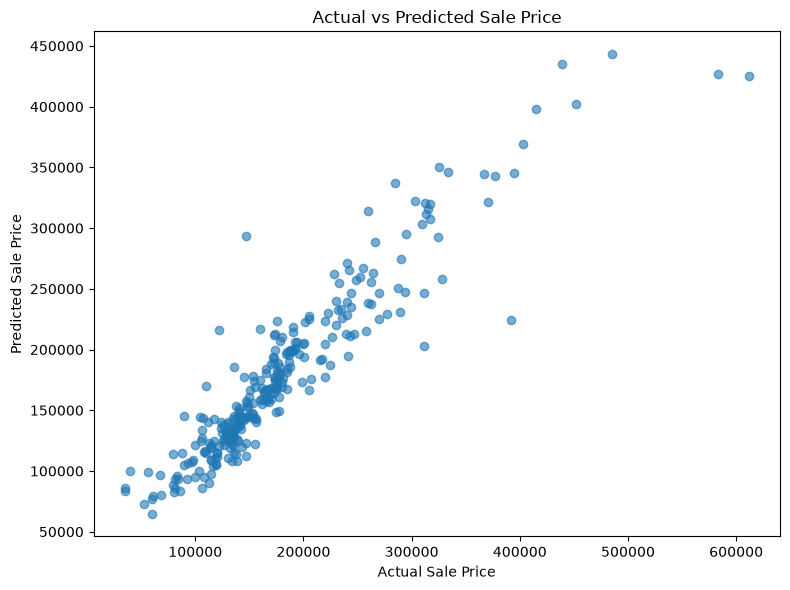

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_val,
    preds,
    alpha=0.6
)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted Sale Price")

plt.tight_layout()

plt.savefig("../docs/images/actual_vs_predicted.png")

plt.show()

## Feature Importance Analysis

Feature importance scores from the Random Forest
model were used to identify the variables that
contribute most strongly to house price prediction.

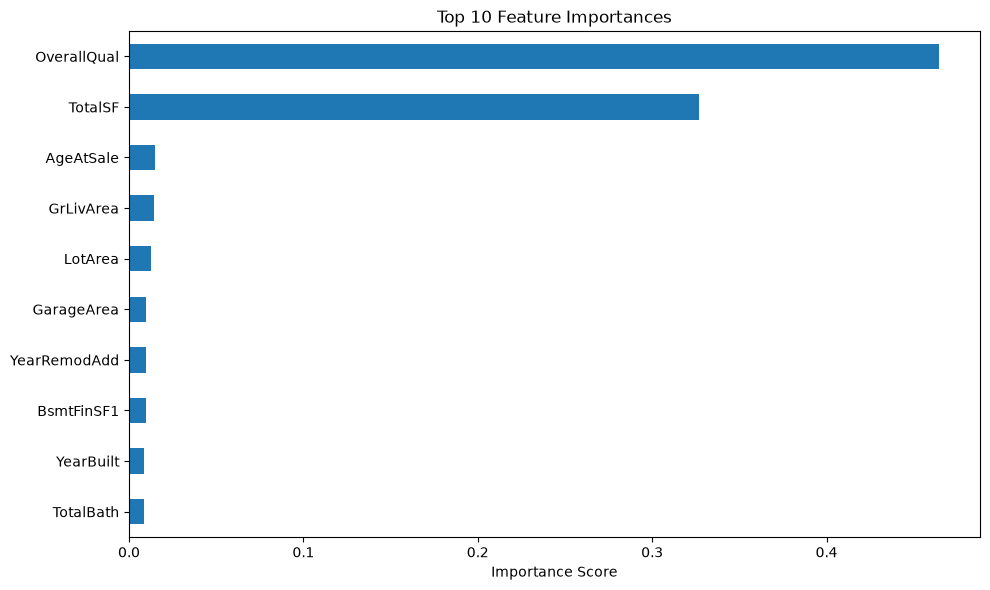

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))

feature_importance.head(10).sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Feature Importances")
plt.xlabel("Importance Score")

plt.tight_layout()

plt.savefig("../docs/images/feature_importance.png")

plt.show()

## Model Export

The trained Random Forest model is exported as `model.pkl`.

This file is used by the Streamlit dashboard to generate
house price predictions for user-provided property characteristics.

In [23]:
# Export the trained Random Forest model.
# This model will be loaded later by the Streamlit application
# to generate house price predictions.
import joblib
joblib.dump(model, "model.pkl")
print("model.pkl saved successfully.")


model.pkl saved successfully.
